## System und Impulsantwort
## Was ist ein System?

Ein System ist ein Prozess, der ein Ausgangssignal als Antwort auf ein Eingangssignal produziert.

<img src="attachments/system.png" width="900">

Ein Signal beschreibt wie ein Parameter sich auf einen anderen bezieht:

Weg <- -> Zeit  

Nomenklatur:
- Kontinuierliche Signale:		x(t), y(t)
- Diskrete Signale:		    	x[n], y[n]
- Zeitbereich: 			        x(..)
- Frequenzbereich:		        X(..)





## Systemeigenschaften

Auf den ersten Blick mag es wie eine überwältigende Aufgabe erscheinen, alle möglichen Systeme in der Welt zu verstehen. Glücklicherweise fallen die meisten nützlichen Systeme in eine Kategorie, die als lineare Systeme bezeichnet wird.

Die meisten Techniken der digitalen Signalverarbeitung (DSP) basieren auf einer Strategie des „Teile-und-herrsche“-Prinzips, die als Superposition bekannt ist. Dabei wird das zu verarbeitende Signal in einfache Komponenten zerlegt, jede Komponente wird einzeln verarbeitet, und die Ergebnisse werden anschließend wieder zusammengeführt.

Dieser Ansatz hat die enorme Stärke, ein einziges kompliziertes Problem in viele einfache Teilprobleme zu zerlegen. Die Superposition kann jedoch nur bei linearen Systemen angewendet werden – ein Begriff, der bedeutet, dass bestimmte mathematische Regeln gelten. Glücklicherweise gehören die meisten Anwendungen, die in Wissenschaft und Technik auftreten, zu dieser Kategorie. ([[1]](#1))

**Linearität**, **Zeitinvarianz**, **Kausalität** und **Stabilität** sind grundlegende Eigenschaften, mit denen Systeme beschrieben und analysiert werden können. Sie helfen zu verstehen, wie ein System auf verschiedene Eingaben reagiert und ob es sich vorhersagbar verhält.

### Linearität
Ein System ist **linear**, wenn es die Eigenschaften der **Homogenität** (Skalierung) und **Additivität** (Superposition) erfüllt:
- **Homogenität**:

![alt text](attachments/homogenität.png)

- **Additivität**:

![alt text](attachments/additivitaet.png)

**Superpositionsprinzip**: Ein System, das sowohl additiv als auch homogen ist, wird als linear bezeichnet und unterliegt dem Superpositionsprinzip. 
Die Antwort eines linearen Systems zur Summe aus mehreren Signale ist gleich die Summe der einzelnen Antworten  


### Verschiebungsinvarianz
Ein System ist **verschiebungsinvarianz**, wenn eine Verschiebung des Eingangssignals zu einer gleich verschobenen Ausgabe führt.  
![alt text](attachments/verschiebungsinvarianz.png)

### Kausalität
Ein System ist **kausal**, wenn der aktuelle Ausgang nur von gegenwärtigen und vergangenen Eingaben abhängt — niemals von zukünftigen Werten.





**📝 Aufgabe 1: Test auf Linearität**
Testen Sie, ob das System linear ist, basierend auf dem Superpositionsprinzip.

In [1]:
# Setup: Install required libraries
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def system(x):
    y = np.zeros_like(x)
    for n in range(1, len(x)):
        y[n] = x[n] + 2*x[n-1]
    return y

In [3]:
# Create two signals
x1 = np.random.rand(100)
x2 = np.random.rand(100)
a, b = 2, -1

lhs = system(a*x1 + b*x2)
rhs = a*system(x1) + b*system(x2)

print("Linear?", np.allclose(lhs, rhs))

Linear? True


**📝  Aufgabe 2: Test auf Zeitinvarianz**
Verzögern Sie den Eingang und prüfen Sie, ob die Ausgangsverzögerung übereinstimmt.

Time Invariant? True


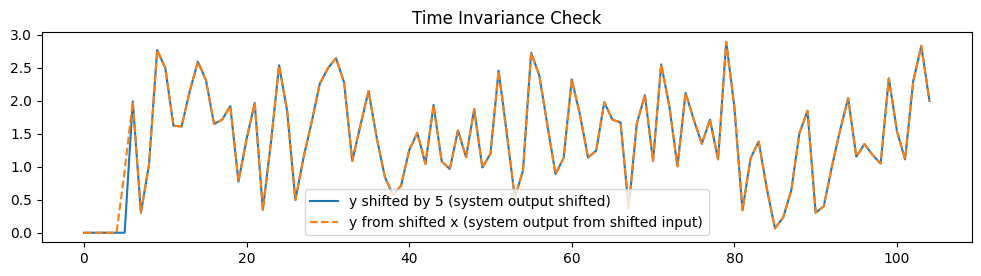

In [4]:
#check for time invariance
x0 = np.random.rand(100)
y0 = system(x0)
shift = 5
#reindex the signal to create a shifted version
x_shifted = np.concatenate((np.zeros(shift), x0))
y_shifted_1 = np.concatenate((np.zeros(shift), y0))
y_shifted_2 = system(x_shifted)

# Compare only after the transient (to ignore boundary zeros)
comparison = np.allclose(y_shifted_1[shift+1:], y_shifted_2[shift+1:])

print("Time Invariant?", np.allclose(y_shifted_1[shift+1:], y_shifted_2[shift+1:]))



#plot the shifted signals
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(y_shifted_1, label='y shifted by 5 (system output shifted)')
plt.plot(y_shifted_2, label='y from shifted x (system output from shifted input)', linestyle='--')
plt.legend()
plt.title('Time Invariance Check')
plt.show()


**📝 Aufgabe 3: Kausalität**
Hängt der Systemausgang nur von aktuellen/vergangenen Eingängen ab?

Causal? True


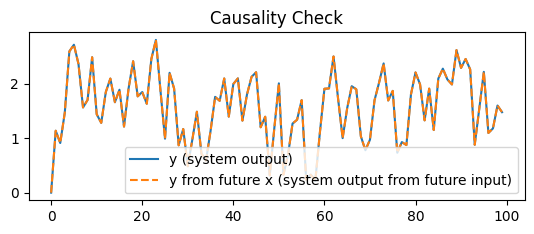

In [5]:
#check for causality
x = np.random.rand(100)
y = system(x)
#make a future version of x
x_future = np.concatenate((x, np.random.rand(10)))
y_future = system(x_future)
#compare the first 100 samples of y and y_future
print("Causal?", np.allclose(y, y_future[:100]))
#plot the signals
plt.subplot(2, 1, 2)
plt.plot(y, label='y (system output)')
plt.plot(y_future[:100], label='y from future x (system output from future input)', linestyle='--')
plt.legend()
plt.title('Causality Check')
plt.show()


## Delta-Funktion (Dirac-Impuls)
Die Delta-Funktion ist ein grundlegendes Konzept in der Signalverarbeitung und Systemtheorie. Die Deltafunktion ist die normalisierte Impulsantwort, wobei der Wert (bei x=0) gleich 1 ist und alle anderen Werte gleich 0 sind. In diskreten Systemen ist sie definiert als:

$$ \delta[n] = \begin{cases} 1, & n = 0 \\ 0, & \text{otherwise} \end{cases} $$

Einer Deltafunktion, welche durch ein System geführt wird. Die Impulsantwort ist dabei der Output. 

<img src="attachments/delta.png" width="800">


- Impulsantwort ist das Signal welches als Ausgangssignal erzeugt wird, wenn die Deltafunktion dem System als Input gegeben wird ℎ[𝑛]
- Beim digitalen Filterdesign wird Impulsantwort auch Filter Kernel, Faltungskernel oder Kernel genannt (auch relevant in der Bildverarbeitung)


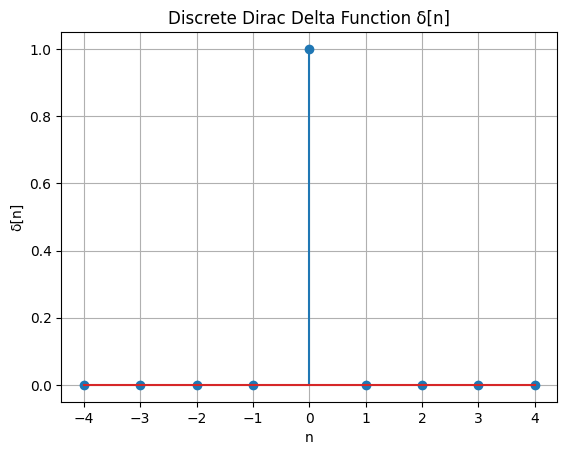

In [6]:
# Discrete time samples from -2 to 2
n = np.arange(-4, 5)  # [-2, -1, 0, 1, 2]

# Create discrete delta (impulse) function
delta = np.zeros_like(n)
delta[n == 0] = 1  # Impulse at n = 0

# Plot
plt.stem(n, delta)
plt.title("Discrete Dirac Delta Function δ[n]")
plt.xlabel("n")
plt.ylabel("δ[n]")
plt.grid(True)
plt.show()

## Impulsantwort
Die Antwort eines Systems auf einen Delta-Eingang δ[n] definiert dessen Impulsantwort h[n].

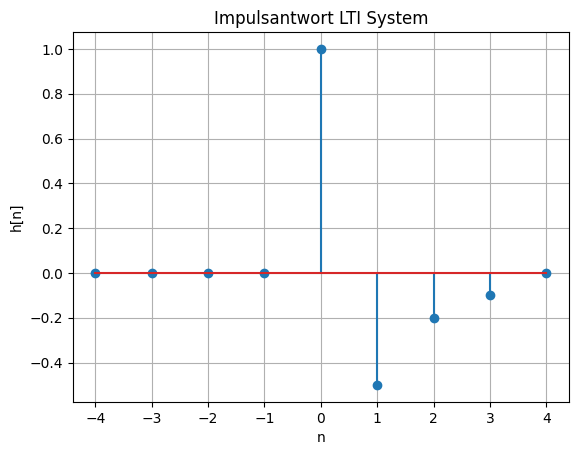

In [7]:
# Simple system: y[n] = x[n] - 0.5 * x[n-1] - 0.2 * x[n-2] - 0.1 * x[n-3]
def lti_system(x):
    y = np.zeros_like(x, dtype=float)
    for n in range(len(x)):
        if n >= 0:
            y[n] += x[n]
        if n >= 1:
            y[n] += -0.5 * x[n-1]
        if n >= 2:
            y[n] += -0.2 * x[n-2]
        if n >= 3:
            y[n] += -0.1 * x[n-3]
    return y

impulsantwort = lti_system(delta)

plt.stem(n, impulsantwort)
plt.title("Impulsantwort LTI System")
plt.xlabel("n")
plt.ylabel("h[n]")
plt.grid(True)
plt.show()

## Systemantwort

**📝 Aufgabe 4:** 

Verwenden Sie die Faltung, um den Systemausgang für einen bekannten Eingang und eine Impulsantwort zu berechnen.

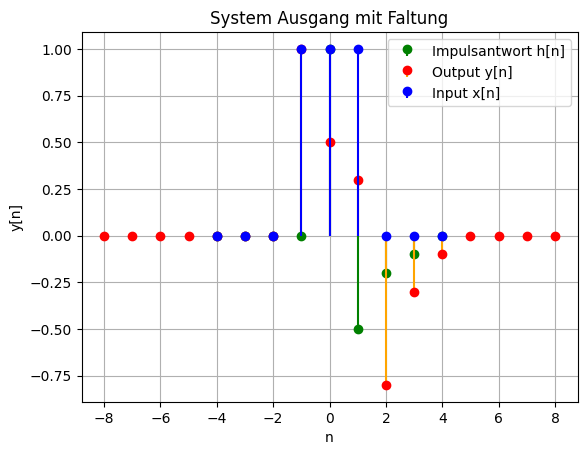

In [8]:
from scipy.signal import convolve

x = np.where((n >= -1) & (n <= 1), 1.0, 0.0)
h = impulsantwort # Impulse response
y = convolve(x, h) # Convolution result
n_y = np.arange(n[0] + n[0], n[-1] + n[-1] + 1)  # [-4, -3, -2, -1, 0, 1, 2, 3, 4]
#plt.plot(n_y, y, label='Output y(n) =', color='orange')
plt.stem(n, impulsantwort, label='Impulsantwort h[n]', linefmt='green', markerfmt='go', basefmt=' ')
plt.stem(n_y, y, label='Output y[n]', linefmt='orange', markerfmt='ro', basefmt=' ')
plt.stem( n, x, label='Input x[n]', linefmt='blue', markerfmt='bo', basefmt=' ')
plt.title("System Ausgang mit Faltung")
plt.legend()
plt.xlabel("n")
plt.ylabel("y[n]")
plt.grid(True)
plt.show()

**📝 Aufgabe 4:**
Verändern Sie die Eingangsform oder die Impulsantwort. Wie wirkt sich das auf den Ausgang aus?

**Quellen und Weiterführende Literatur:**

<a id="1">[1]</a> Smith, Steven W. (1997), The scientist and engineer's guide to digital signal processing. 1. ed. San Diego, Calif.: California Technical Publ. Online verfügbar unter https://www.dspguide.com/.